# 06 · Como BH se posiciona em segurança?

> Parte 6 de 6 do projeto *BH e Região sob a perspectiva dos dados*. Veja o [README](../README.md) para a visão geral.

In [1]:
# Configuração: funciona no computador (a partir da pasta notebooks/) e no Google Colab
import os
import subprocess
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo = Path('/content/ips-bh-rmbh')
    if not repo.exists():
        subprocess.run(['git', 'clone', '-q', 'https://github.com/millebns/ips-bh-rmbh.git', str(repo)], check=True)
    os.chdir(repo / 'notebooks')

sys.path.insert(0, str(Path.cwd().parent / 'src'))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from functools import partial

from ips_rmbh import analise
from ips_rmbh.config import BH, COR_BH, COR_OUTROS, COR_DESTAQUE, PASTA_FIGURAS
from ips_rmbh.dados import carregar_rmbh

df_rmbh = carregar_rmbh()

# Atalhos que comparam BH com os demais municípios da RMBH
posicao_bh = partial(analise.posicao, df_rmbh)
valor_bh = partial(analise.valor, df_rmbh)
print(df_rmbh.shape)

(34, 78)


In [3]:
print(f"Segurança Pessoal: BH {posicao_bh('Segurança Pessoal')}º de 34 | "
      f"nota {valor_bh('Segurança Pessoal'):.2f} | mediana {df_rmbh['Segurança Pessoal'].median():.2f}")

Segurança Pessoal: BH 15º de 34 | nota 67.41 | mediana 67.00


Os indicadores do componente Segurança Pessoal são taxas, então menor é melhor. As violências contra mulheres, negros e indígenas pertencem ao componente Inclusão Social (analisado na pergunta 2), e não a Segurança Pessoal.

In [4]:
seguranca = ['Homicídios', 'Assassinatos de Jovens', 'Assassinatos de Mulheres',
             'Mortes por Acidentes de Transporte']

pd.DataFrame([{
    'indicador': c,
    'BH': round(valor_bh(c), 2),
    'mediana_RMBH': round(df_rmbh[c].median(), 2),
    'posicao_BH': posicao_bh(c, maior_melhor=False),
} for c in seguranca])

,indicador,BH,mediana_RMBH,posicao_BH
0,Homicídios,13.91,14.00,16
1,Assassinatos de Jovens,30.31,28.95,19
2,Assassinatos de Mulheres,2.35,2.41,17
3,Mortes por Acidentes de Transporte,10.91,5.68,26


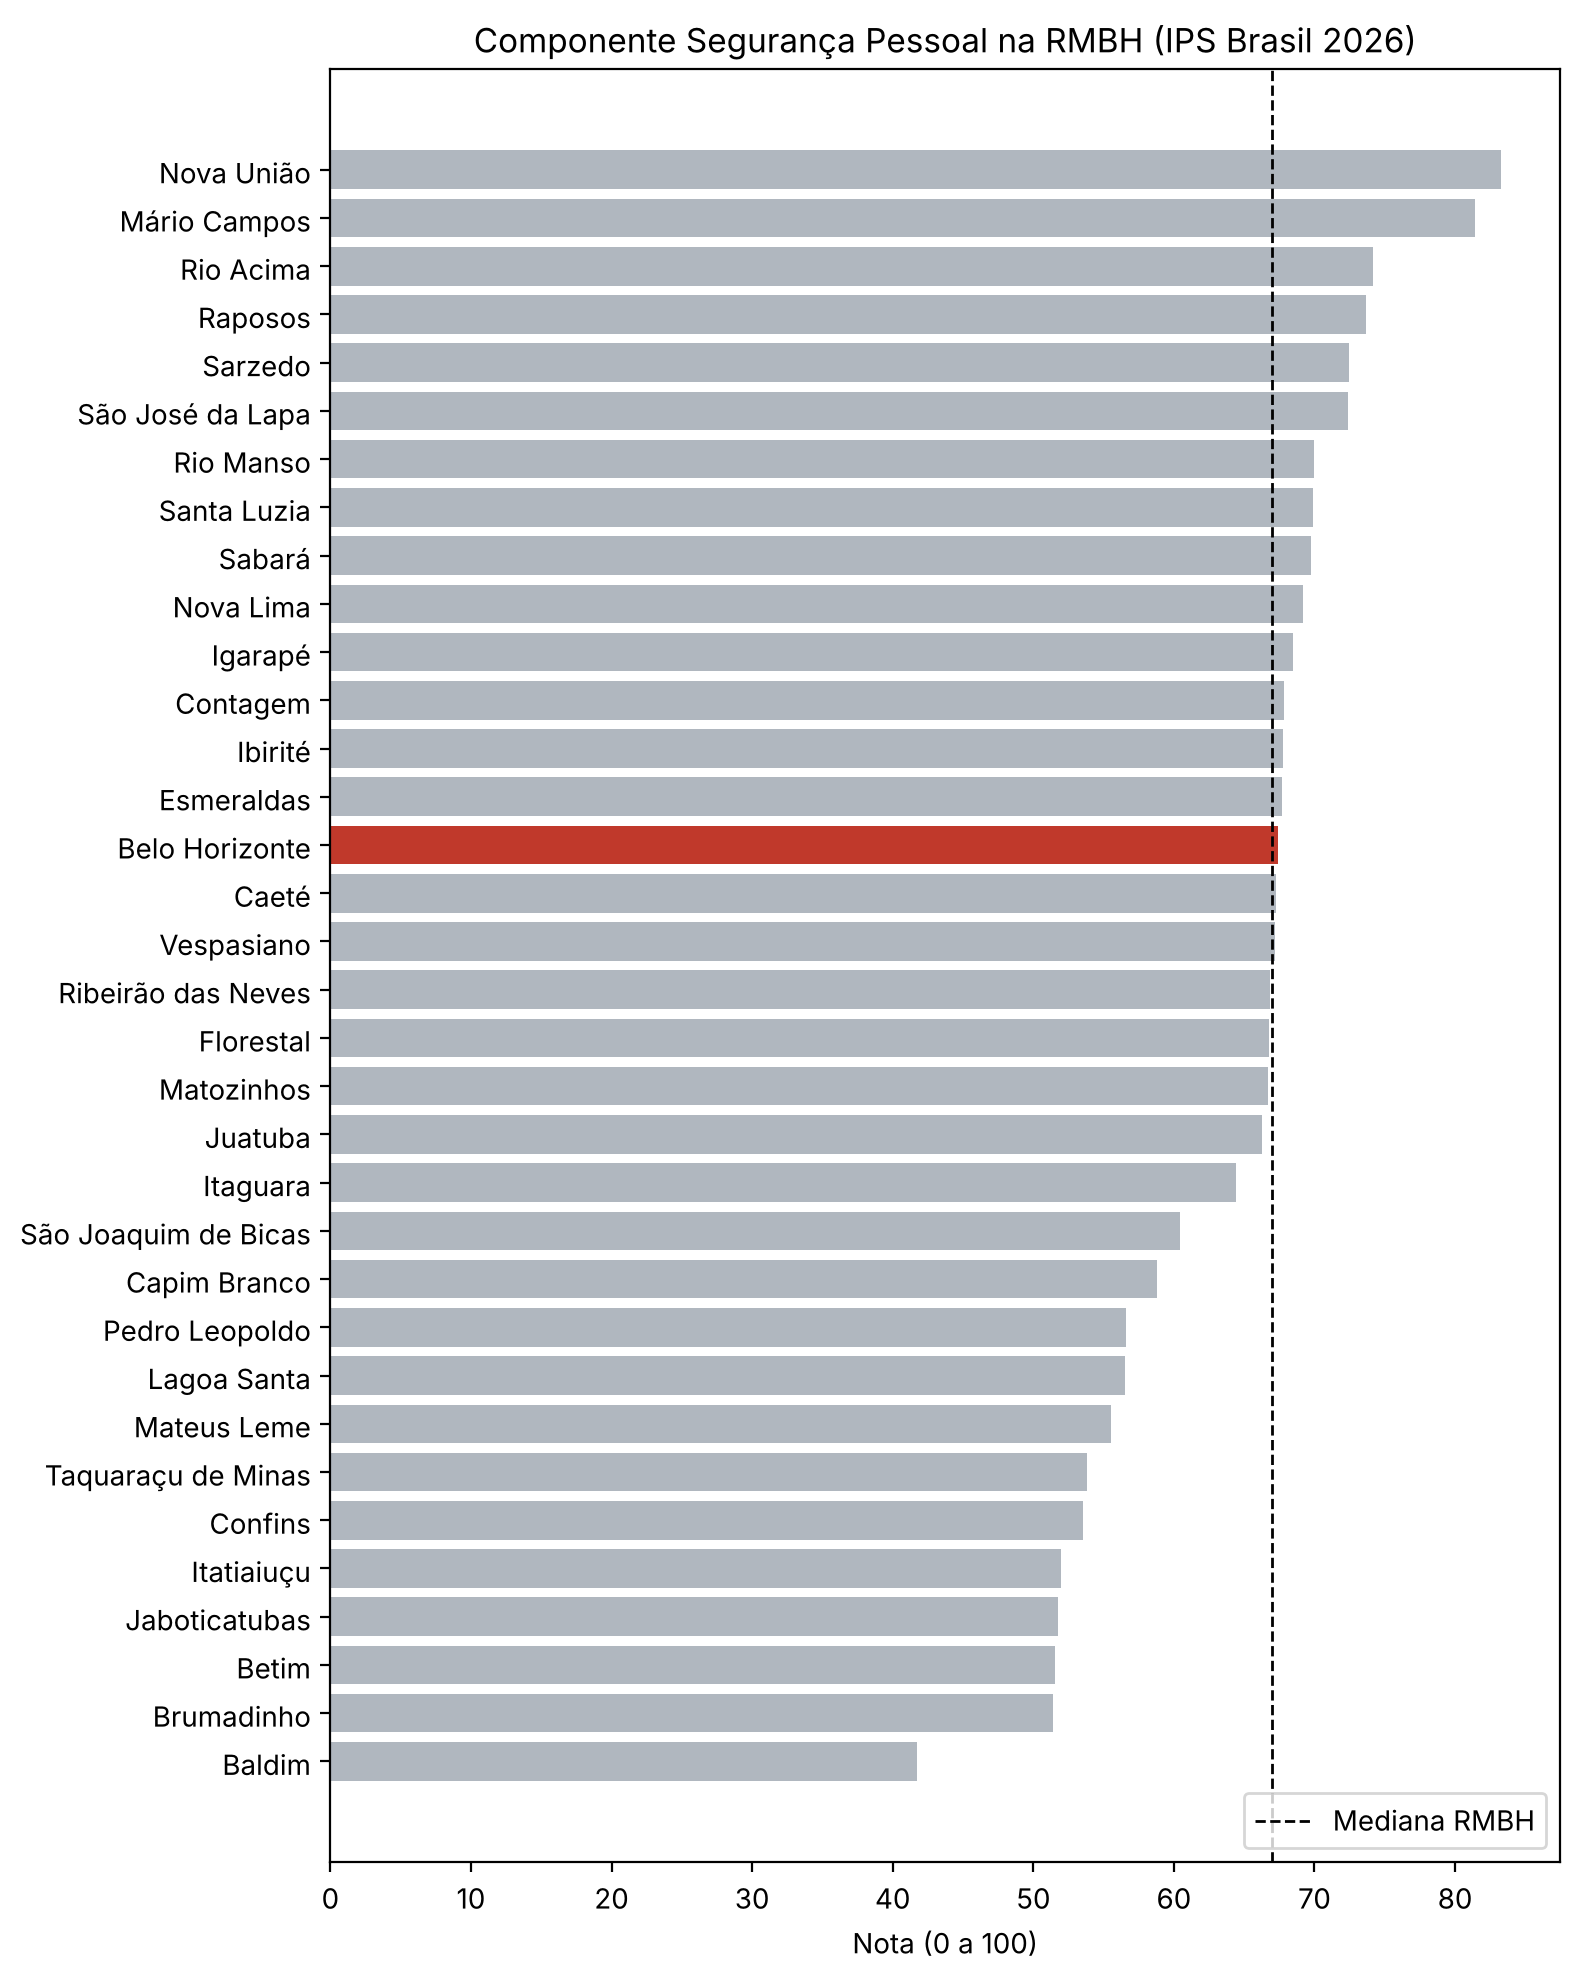

In [5]:
seg = df_rmbh[['Município', 'Segurança Pessoal']].sort_values('Segurança Pessoal')

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(seg['Município'], seg['Segurança Pessoal'],
        color=[COR_BH if m == BH else COR_OUTROS for m in seg['Município']])
ax.axvline(seg['Segurança Pessoal'].median(), ls='--', c='black', lw=1, label='Mediana RMBH')
ax.set_title('Componente Segurança Pessoal na RMBH (IPS Brasil 2026)')
ax.set_xlabel('Nota (0 a 100)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / '04_seguranca_rmbh.png', dpi=150, bbox_inches='tight')
plt.show()

Resposta: BH fica no meio da tabela em segurança (15ª de 34), com nota praticamente igual à mediana. A taxa de homicídios de BH (13,9) é quase idêntica à mediana regional (14,0). O indicador em que BH vai pior são as mortes por acidentes de transporte (10,9 contra 5,7; 26ª posição). As menores notas de segurança da região estão em Baldim, Brumadinho e Betim.

# Conclusões do projeto

1. **BH está entre os maiores IPS da RMBH:** 3ª de 34, praticamente empatada com Confins e atrás de Nova Lima.
2. **O índice alto esconde um perfil desigual:** BH lidera em educação superior, direitos individuais e saneamento, mas é a última em inclusão social, puxada pela população em situação de rua. Em relação à riqueza, BH tem progresso social acima do esperado para o seu PIB per capita.
3. **Em segurança, BH é mediana:** homicídios no nível da região, com pior desempenho nas mortes no trânsito.

## Limitações

- A análise usa apenas a edição 2026. As edições anteriores não são comparáveis por nota, como mostrado na exploração inicial.
- Municípios pequenos têm taxas mais instáveis, o que afeta a leitura de posições próximas no ranking.
- A relação entre IPS e PIB é uma associação entre 34 municípios, não uma relação de causa.